In [59]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [60]:
from pathlib import Path

import pandas as pd
from matplotlib import pyplot as plt
from scipy import stats
import numpy as np
import numpy as np
from scipy.optimize import curve_fit

from notebooks.imports import *
from src.utils import pmf_utils


### Config

In [61]:
from config import dir_config, main_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

### Utils functions

In [62]:
def plot_psych(x, y, x_hat, y_hat) -> None:
    fig, ax = plt.subplots()
    ax.plot(x, y, "o", label="Original Data")
    ax.plot(x_hat, y_hat, "r-", label="Fitted Curve")
    ax.set_xlabel("Coherence")
    ax.set_ylabel("Probability of Correct Response")
    ax.set_xlim(-100, 100)
    ax.set_ylim(0, 1)
    ax.legend()
    plt.show()

def get_pulse_data(data, pulse_type):
    pulse_data = data[(data.pulse_type == pulse_type)]
    if pulse_type > 0:
        # include positive 100 control data too
        positive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == 100)]
        pulse_data = pd.concat([pulse_data, positive_control_data])
    elif pulse_type < 0:
        negavtive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == -100)]
        pulse_data = pd.concat([pulse_data, negavtive_control_data])
    return pulse_data

def plot_pulse_psych(psych_curves, ms=10, lw=3, ls="-", alpha=1.0, suptitle="", marker='o', fig=None, ax=None, legend=True):
    """
    Plot psychometric curves for early, mid, and late pulses with control, positive, and negative conditions.
    """

    # Create figure and axes if not provided
    if fig is None or ax is None:
        fig, ax = plt.subplots(1, 3, figsize=(18, 6))

    # Mapping of pulse stage to subplot index
    pulse_map = {1: 0, 2: 1, 3: 2}
    pulse_labels = {1: "Early Pulse", 2: "Mid Pulse", 3: "Late Pulse"}

    def plot_single_pulse(ax, pulse_id, title):
        """Helper to plot a single pulse stage (early, mid, late)."""
        # Plot control
        ax.plot(psych_curves[0]["x"], psych_curves[0]["y"], "k", marker=marker, ms=ms, alpha=alpha, linestyle='None')
        ax.plot(psych_curves[0]["x_hat"], psych_curves[0]["y_hat"], "k", lw=lw, ls=ls, alpha=alpha, label="Control")
        if psych_curves[0].get("y_err") is not None:
            ax.errorbar(psych_curves[0]["x"], psych_curves[0]["y"], yerr=psych_curves[0]["y_err"], fmt="none", ecolor="k", alpha=alpha)

        # Plot positive pulse
        ax.plot(psych_curves[pulse_id]["x"], psych_curves[pulse_id]["y"], "b", marker=marker, ms=ms, alpha=alpha, linestyle="None")
        ax.plot(psych_curves[pulse_id]["x_hat"], psych_curves[pulse_id]["y_hat"], "b", lw=lw, ls=ls, alpha=alpha, label=f"{title.split()[0]} Positive")
        if psych_curves[pulse_id].get("y_err") is not None:
            ax.errorbar(psych_curves[pulse_id]["x"], psych_curves[pulse_id]["y"], yerr=psych_curves[pulse_id]["y_err"], fmt="none", ecolor="b", alpha=alpha)

        # Plot negative pulse
        ax.plot(psych_curves[-pulse_id]["x"], psych_curves[-pulse_id]["y"], "r", marker=marker, ms=ms, alpha=alpha, linestyle="None")
        ax.plot(psych_curves[-pulse_id]["x_hat"], psych_curves[-pulse_id]["y_hat"], "r", lw=lw, ls=ls, alpha=alpha, label=f"{title.split()[0]} Negative")
        if psych_curves[-pulse_id].get("y_err") is not None:
            ax.errorbar(psych_curves[-pulse_id]["x"], psych_curves[-pulse_id]["y"], yerr=psych_curves[-pulse_id]["y_err"], fmt="none", ecolor="r", alpha=alpha)

        # Formatting
        ax.set(xlabel="Coherence", ylabel="Probability of Positive Response", title=title, xlim=(-105, 105), ylim=(-0.05, 1.05))
        ax.set_xticks(psych_curves[0]["x"])
        ax.tick_params(axis="both", labelsize=16)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(False)
        if legend:
            ax.legend()

    # Iterate through pulse stages that exist in psych_curves
    for pulse_id, idx in pulse_map.items():
        if pulse_id in psych_curves:
            plot_single_pulse(ax[idx], pulse_id, pulse_labels[pulse_id])

    if suptitle:
        fig.suptitle(suptitle, fontsize=24)

    fig.tight_layout()
    return fig, ax

In [63]:
data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
# data = data[data["subject_id"] != "DBM6"]
# data = data[data.reaction_time < main_config.acceptance_criteria.max_reaction_time]


data.groupby("subject_id").agg(n_sessions=("session_id", "nunique"), n_rows=("session_id", "size")).reset_index()


,subject_id,n_sessions,n_rows
0,DBM12,1,959
1,DBM14,3,1780
2,DBM15,2,820
3,DBM5,7,4176
4,DBM6,8,4302
5,PSUIM10,3,1229
6,PSUIM5,6,3002
7,PSUIM6,23,9553
8,PSUIM7,11,7263
9,PSUIM9,3,1048


### Plot psychometric functions

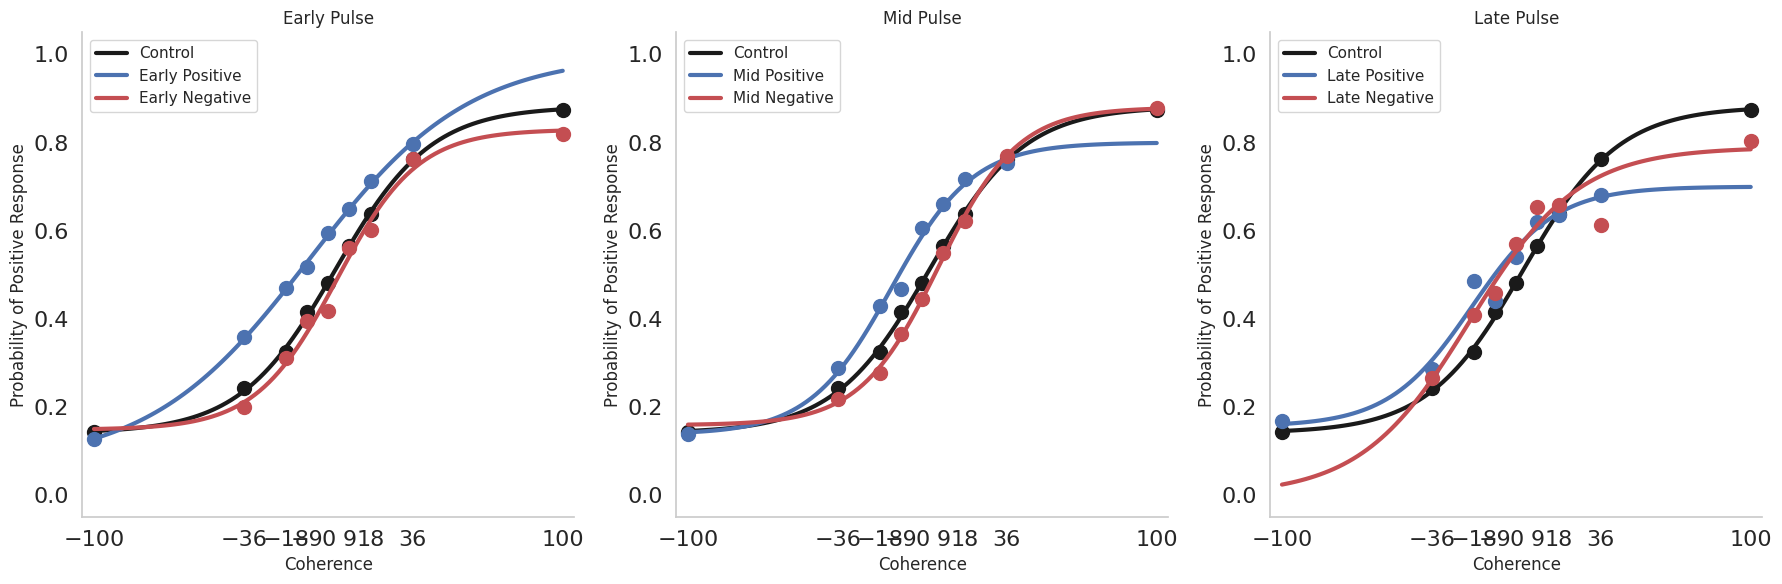

In [7]:
# run utils.get_psychometric_curve function for each subset of pulse_type
psych_curves = {}

for pulse_type in data.pulse_type.unique():


    x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(data, pulse_type), model_type=main_config.psych_model, x_model_range=[-100, 100])

    psych_curves[pulse_type] = {
        "x": x,
        "y": y,
        "model": model,
        "x_hat": x_hat,
        "y_hat": y_hat,
    }

plot_pulse_psych(psych_curves);

In [8]:
# run utils.get_psychometric_curve function for each subset of pulse_type
pmf_data_by_subject = {}
for subject_id in data.subject_id.unique():
    subject_data = data[data.subject_id == subject_id]

    psych_curves = {}

    for pulse_type in subject_data.pulse_type.unique():
        x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(subject_data, pulse_type), model_type=main_config.psych_model, x_model_range=[-100, 100])

        psych_curves[pulse_type] = {
            "x": x,
            "y": y,
            "model": model,
            "x_hat": x_hat,
            "y_hat": y_hat,
        }
    pmf_data_by_subject[subject_id] = psych_curves

-100.0118662693337 30.96670663314928
-109.46155238451139 98.43154214939784
-119.85620711120686 108.8261968760933


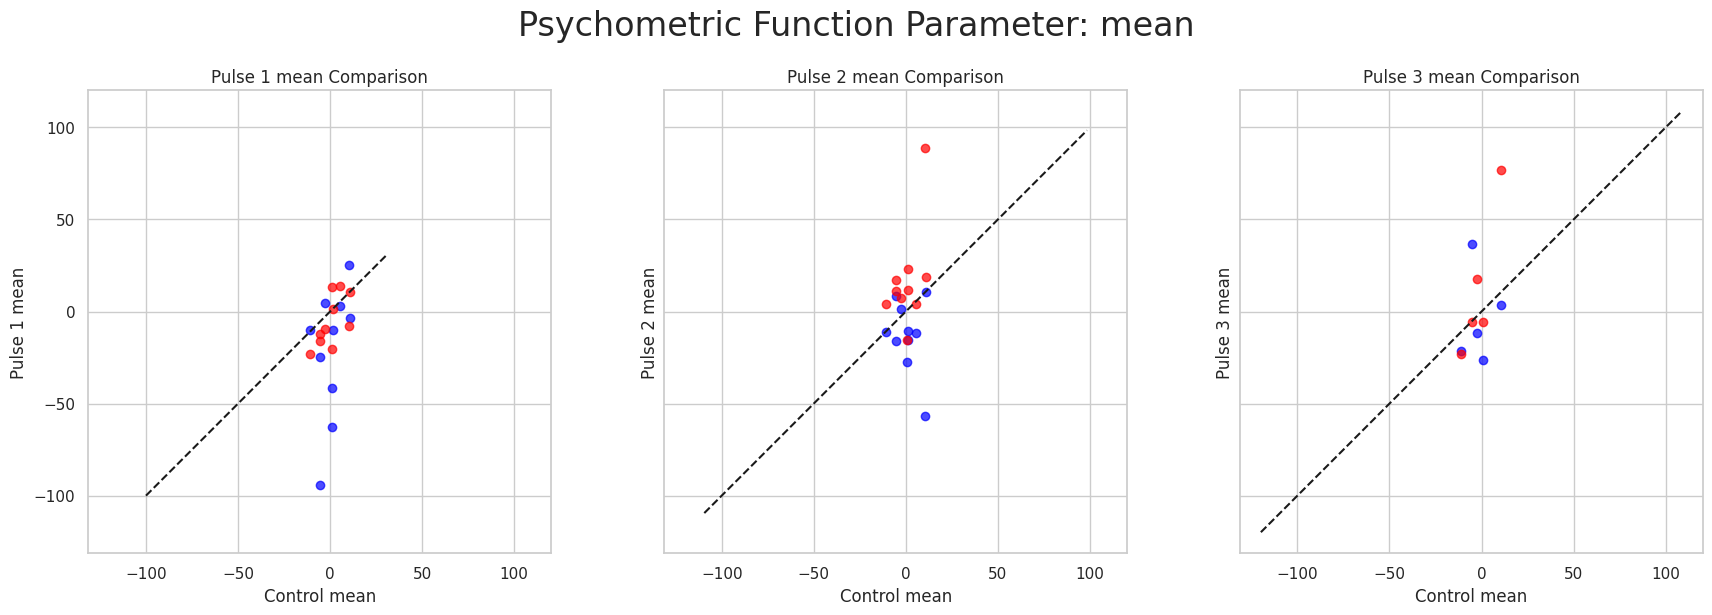

-0.10969205474064471 2.303753149575145
-0.23116324423956142 2.4412029247366056
-0.4484921307489039 4.3327433724566315


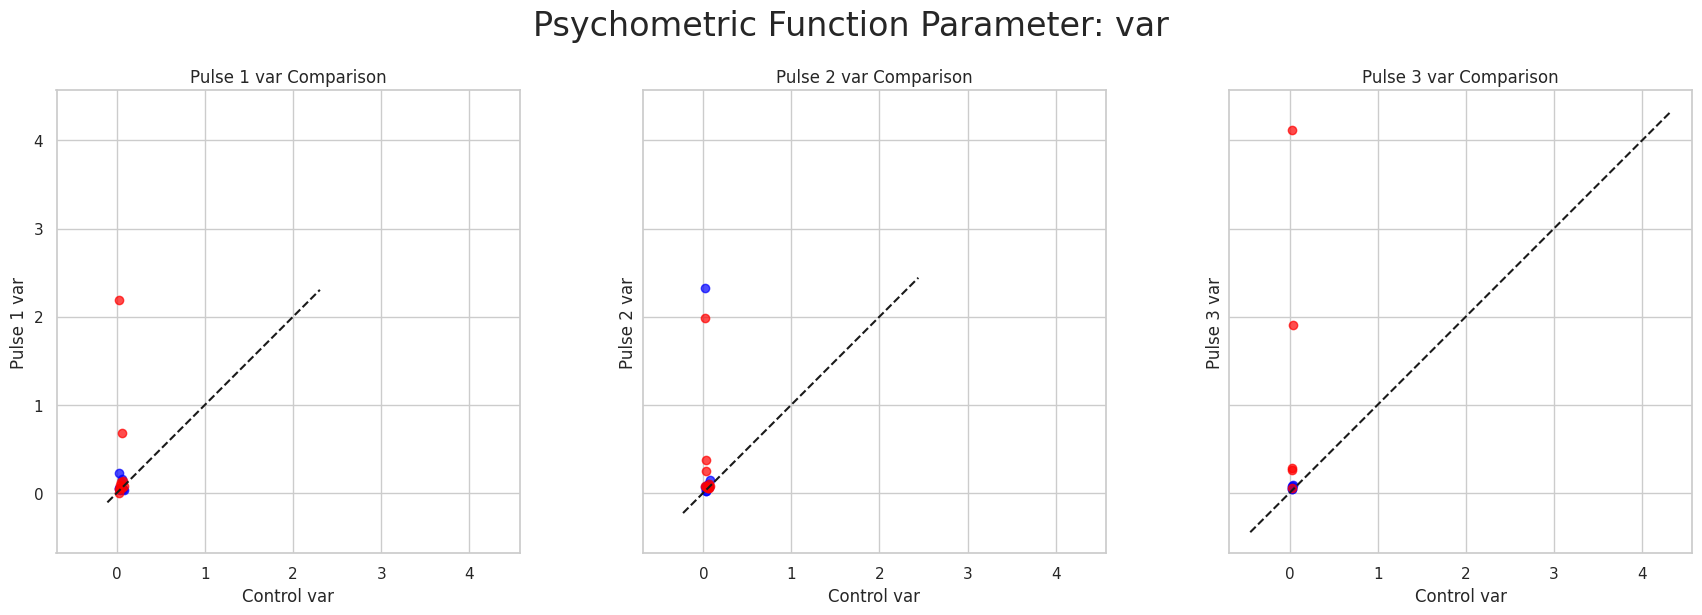

-0.019989463735148122 0.41999873843811053
-0.04198887384381106 0.44199814854677344
-0.06618822496334029 0.46619749966630264


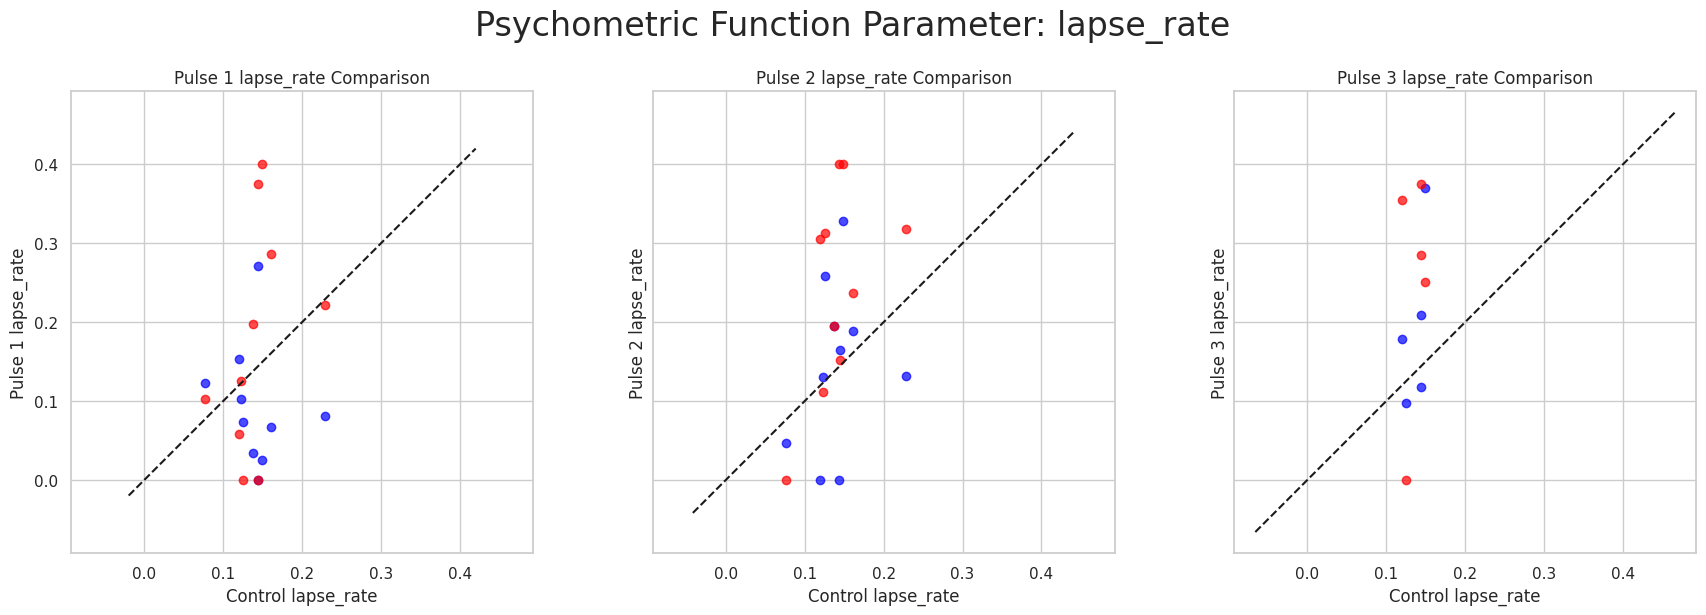

-0.0199895 0.41999949999999997
-0.04198895 0.44199894999999995
-0.066188345 0.46619834499999996


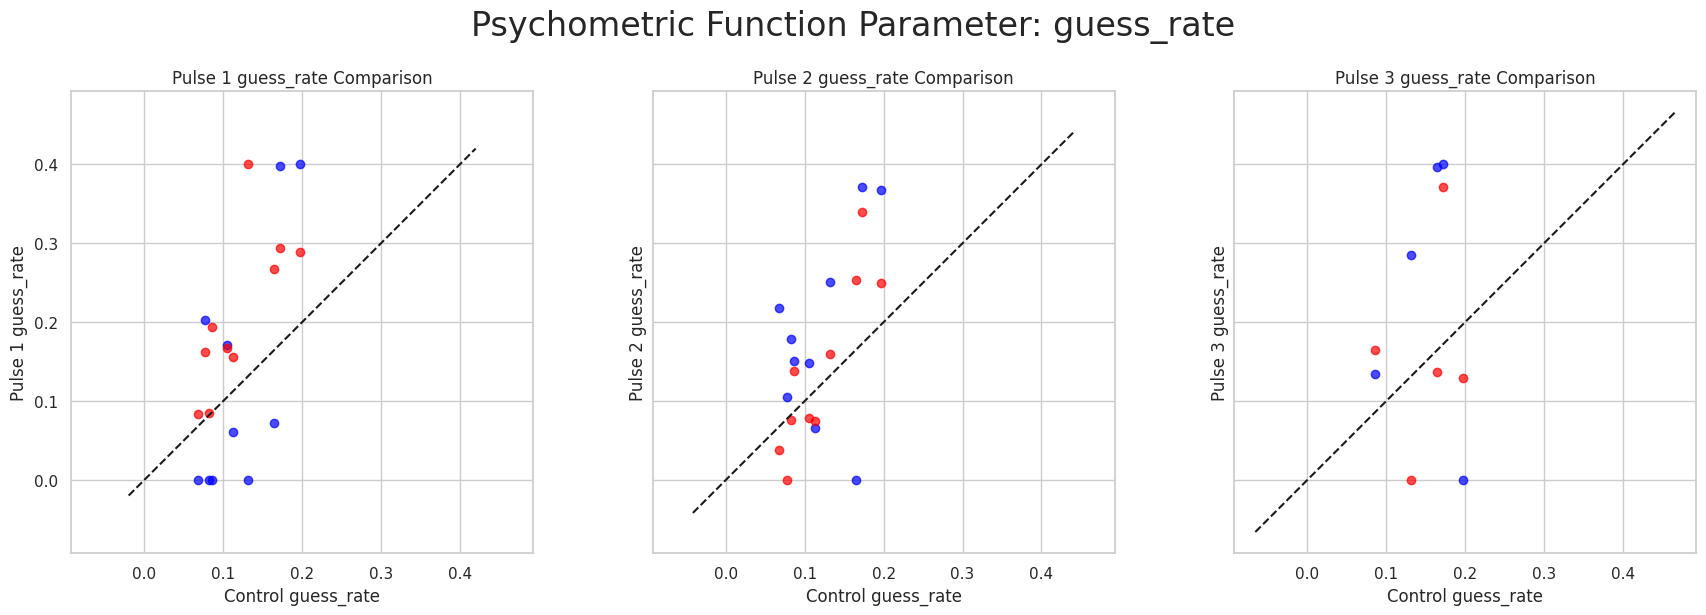

In [9]:
subjects = data.subject_id.unique()

for param_plot in ["mean", "var", "lapse_rate", "guess_rate"]:
    fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

    for idx, pulse in enumerate([1, 2, 3]):
        control, pos, neg = [], [], []
        for subject in subjects:
            if pulse not in pmf_data_by_subject[subject]:
                continue
            control.append(pmf_data_by_subject[subject][0]["model"].coefs_.get(param_plot, np.nan))
            pos.append(pmf_data_by_subject[subject][pulse]["model"].coefs_.get(param_plot, np.nan))
            neg.append(pmf_data_by_subject[subject][-pulse]["model"].coefs_.get(param_plot, np.nan))

        # Scatter plots
        axs[idx].scatter(control, pos, label="Positive Pulse", color="blue", alpha=0.7)
        axs[idx].scatter(control, neg, label="Negative Pulse", color="red", alpha=0.7)
        xlim = axs[idx].get_xlim()
        ylim = axs[idx].get_ylim()
        min_lim = min(xlim[0], ylim[0])
        max_lim = max(xlim[1], ylim[1])
        axs[idx].plot([min_lim, max_lim], [min_lim, max_lim], "k--")
        print(min_lim, max_lim)
        # # Determine matching limits dynamically
        # all_vals = np.array(control + pos + neg)
        # finite_vals = all_vals[np.isfinite(all_vals)]
        # if finite_vals.size > 0:
        #     lim_min, lim_max = np.min(finite_vals), np.max(finite_vals)
        #     pad = 0.1 * (lim_max - lim_min)
        #     lims = [lim_min - pad, lim_max + pad]
        # else:
        #     lims = [-1, 1]  # fallback

        # axs[idx].set_xlim(lims)
        # axs[idx].set_ylim(lims)
        axs[idx].set_aspect("equal", adjustable="box")

        axs[idx].set_xlabel(f"Control {param_plot}")
        axs[idx].set_ylabel(f"Pulse {pulse} {param_plot}")
        axs[idx].set_title(f"Pulse {pulse} {param_plot} Comparison")
        # axs[idx].legend()

    fig.suptitle(f"Psychometric Function Parameter: {param_plot}", fontsize=24)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


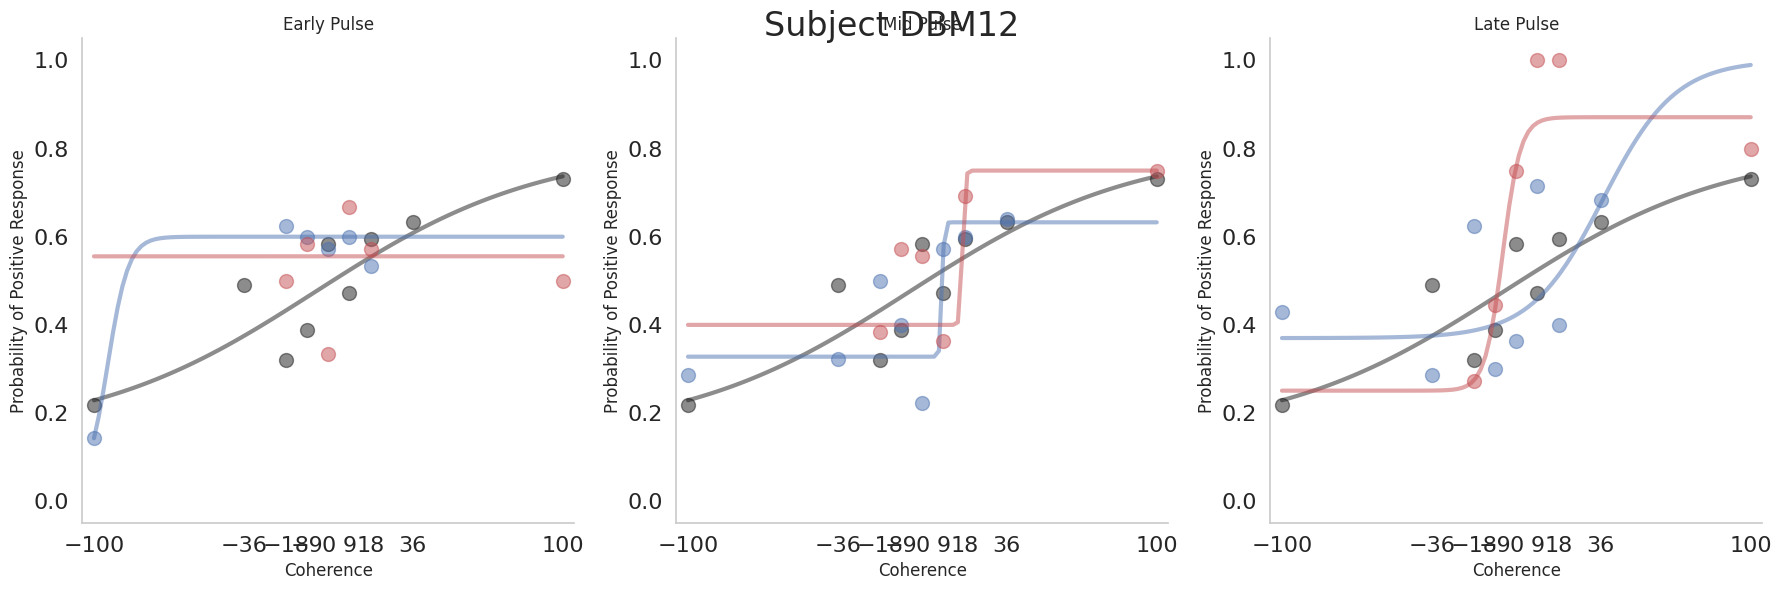

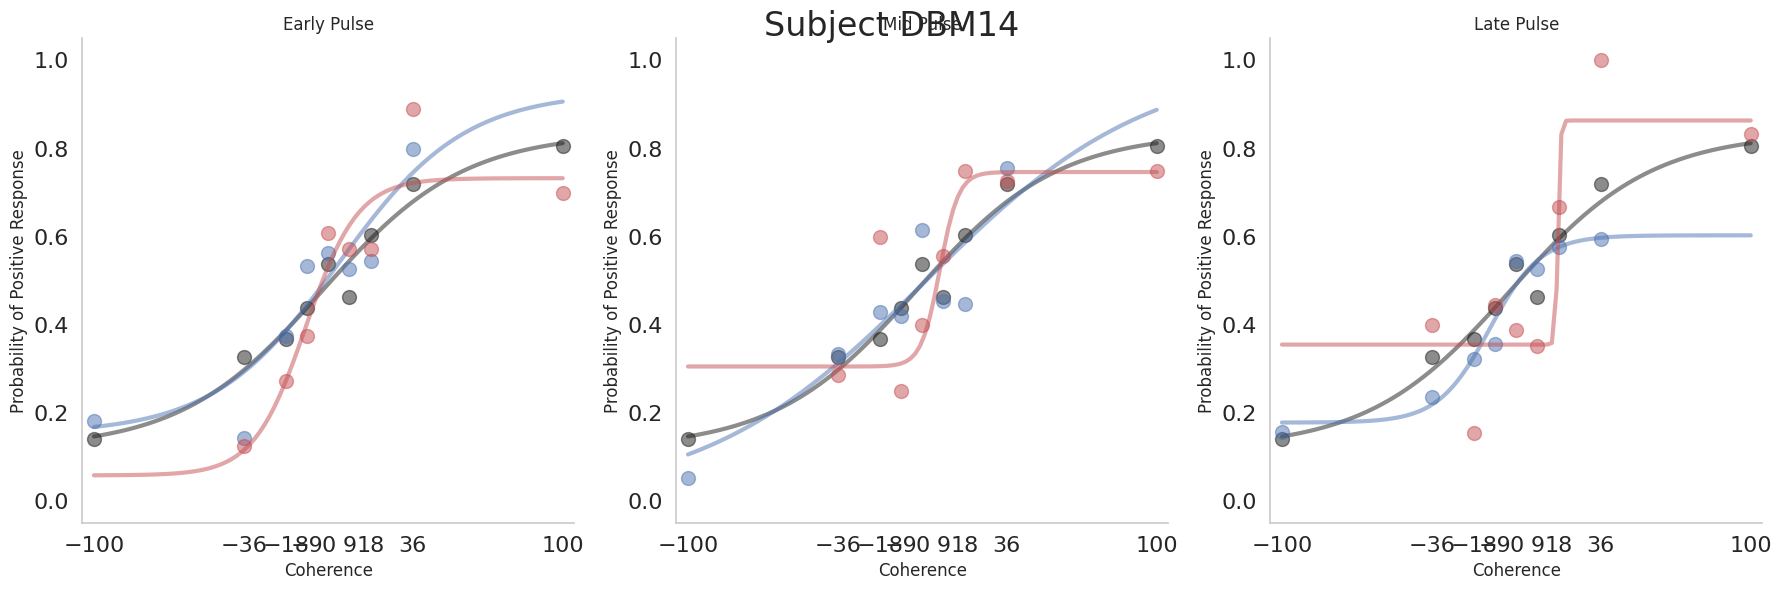

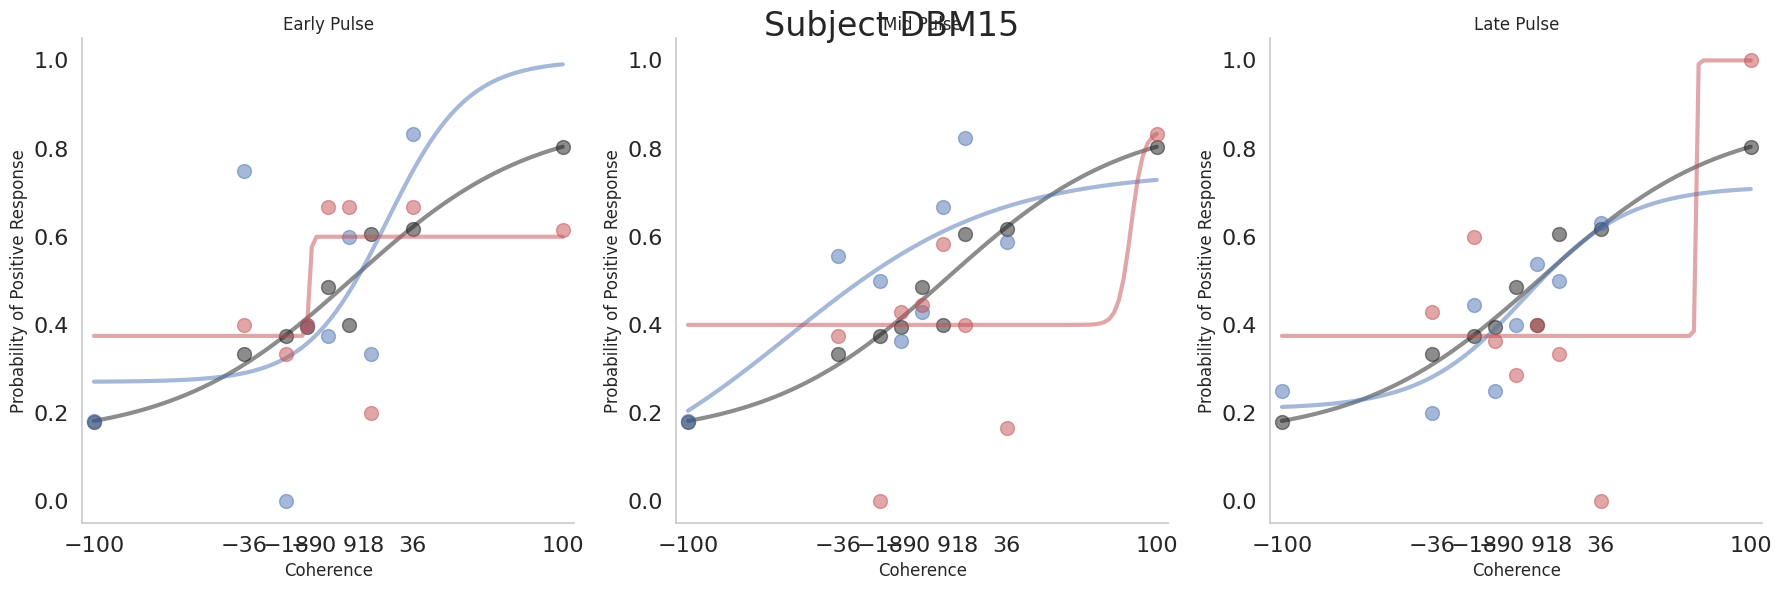

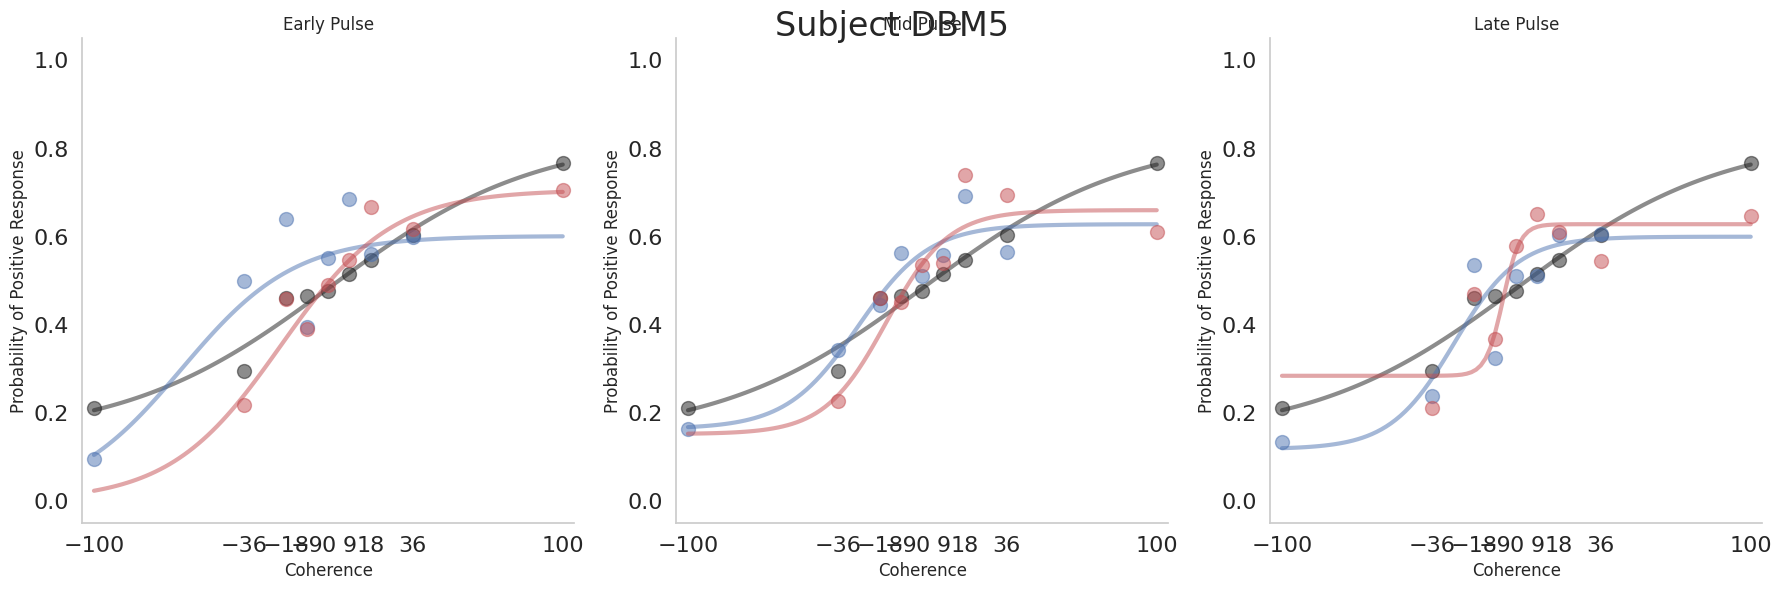

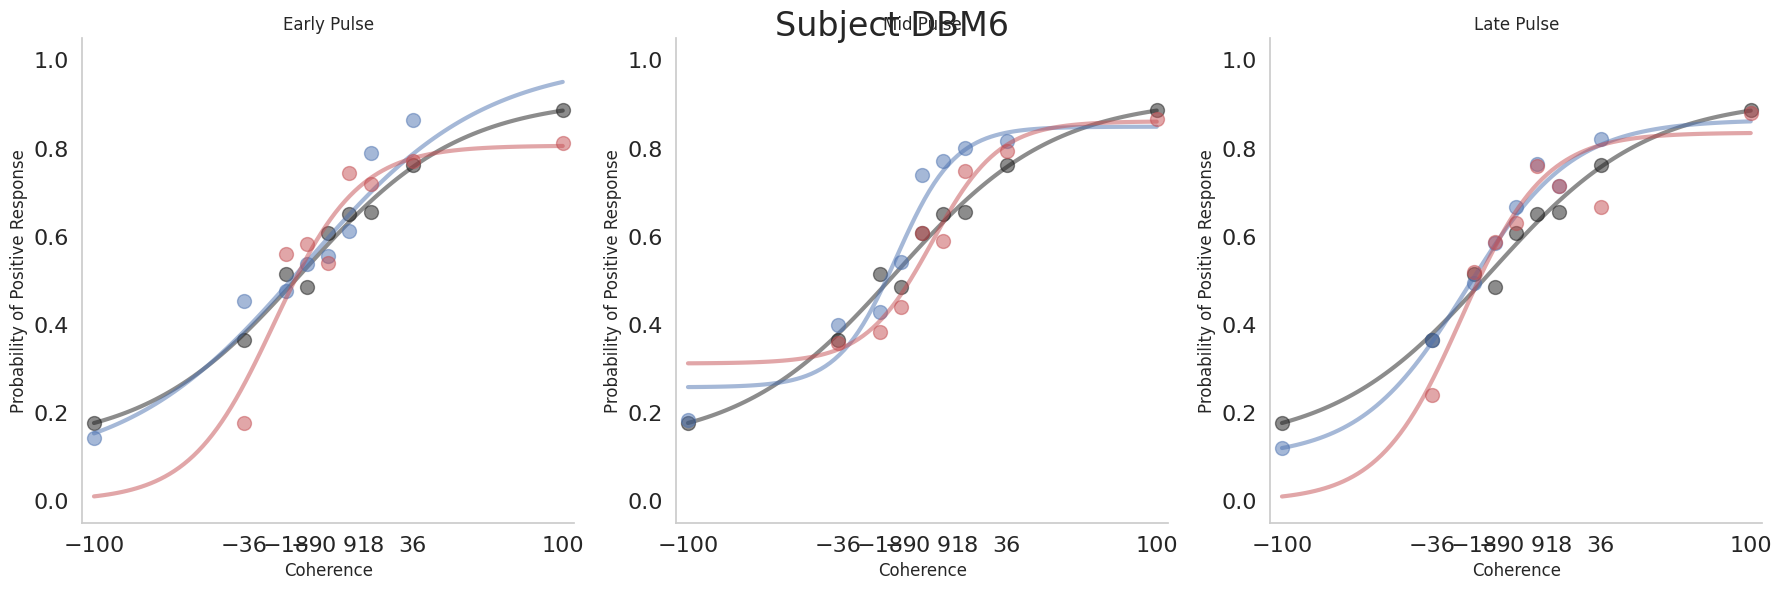

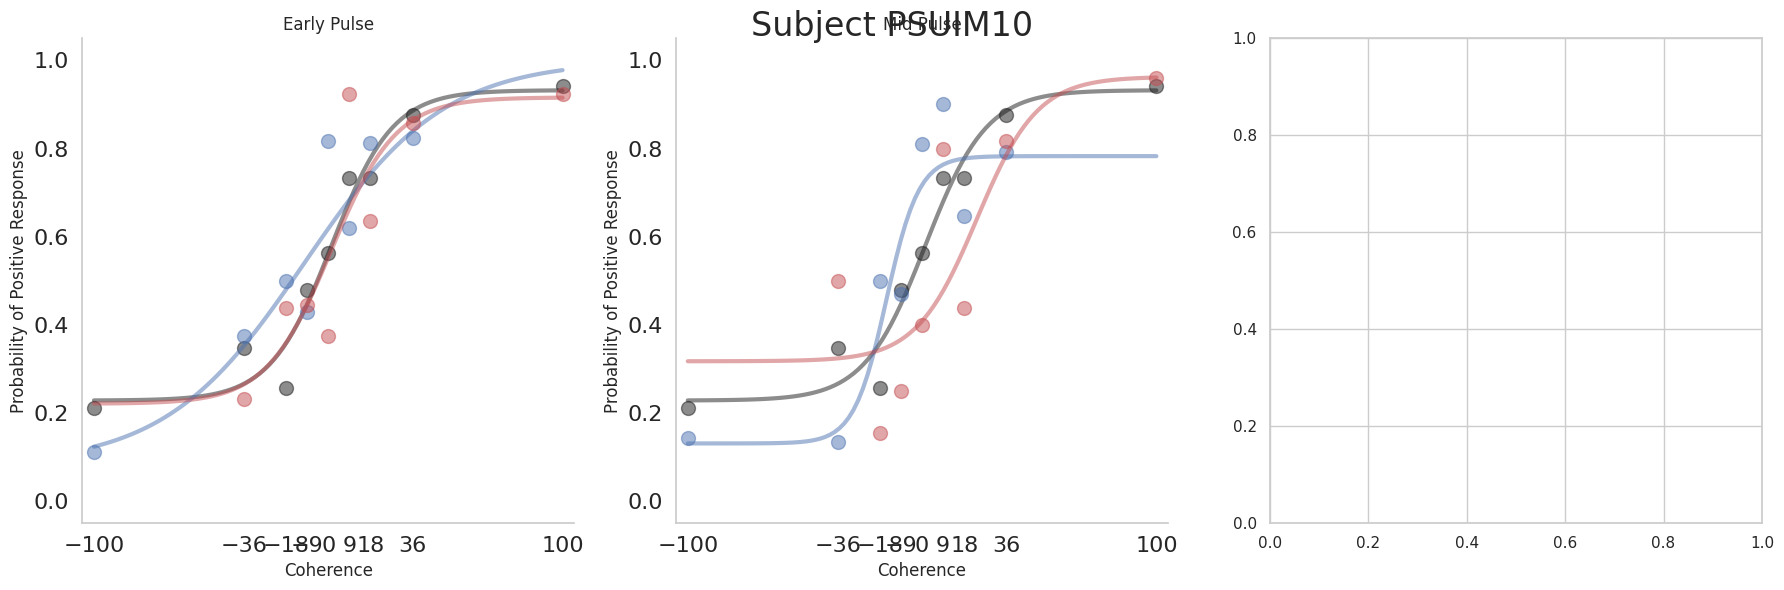

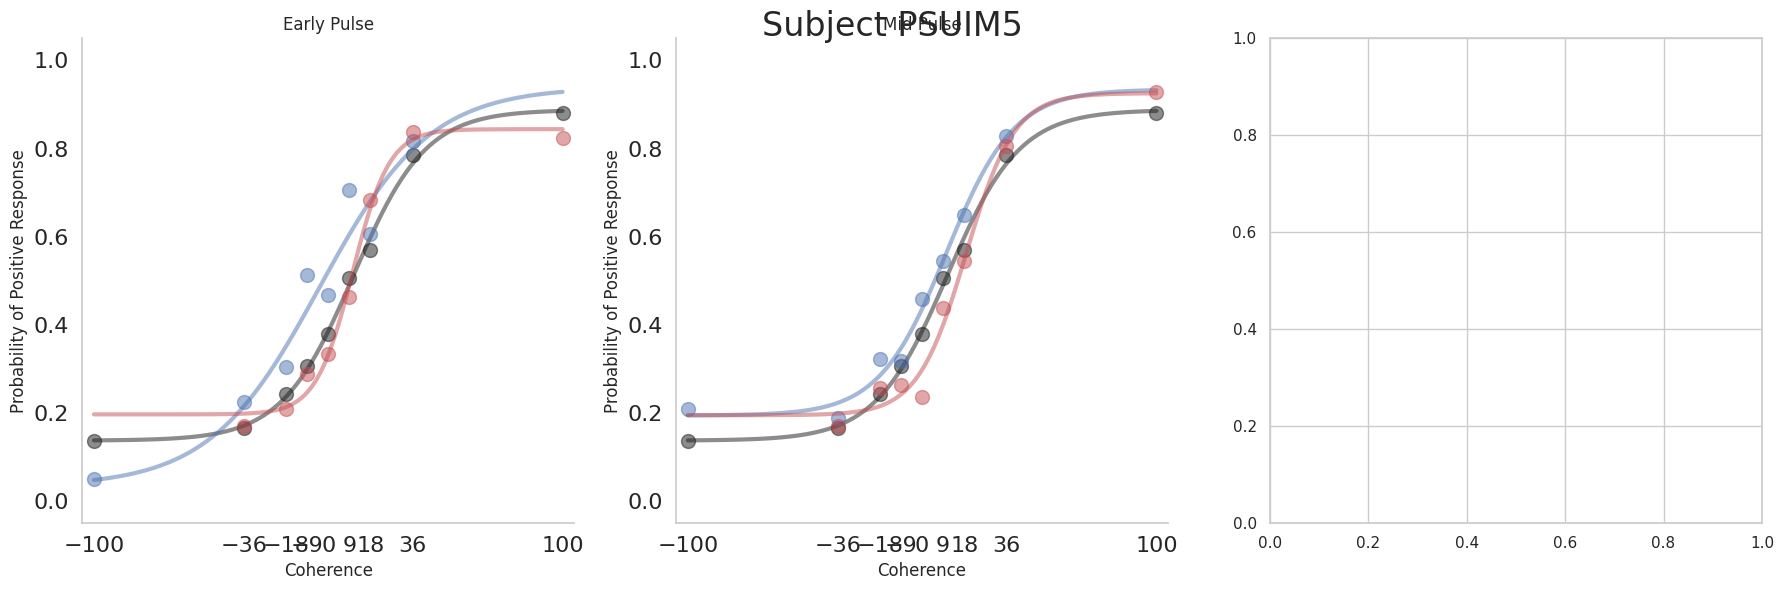

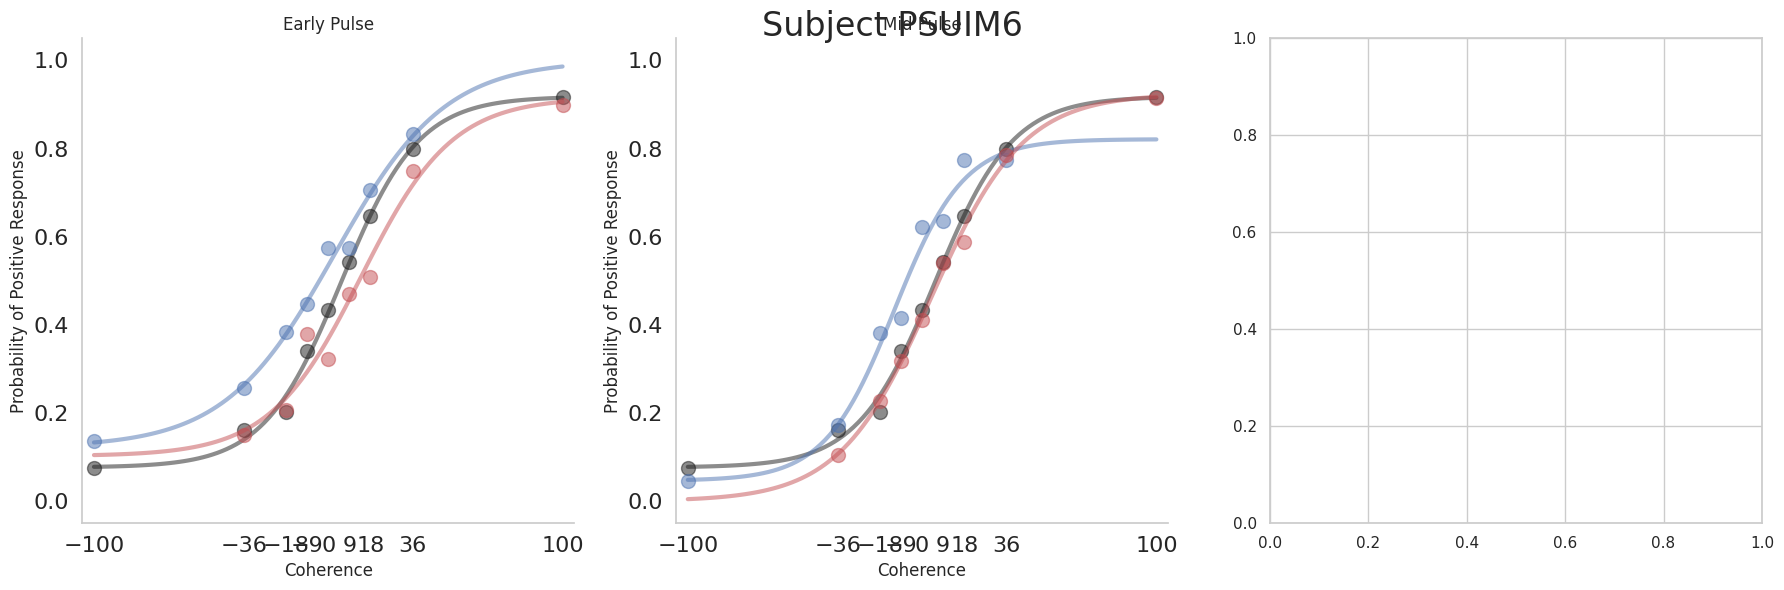

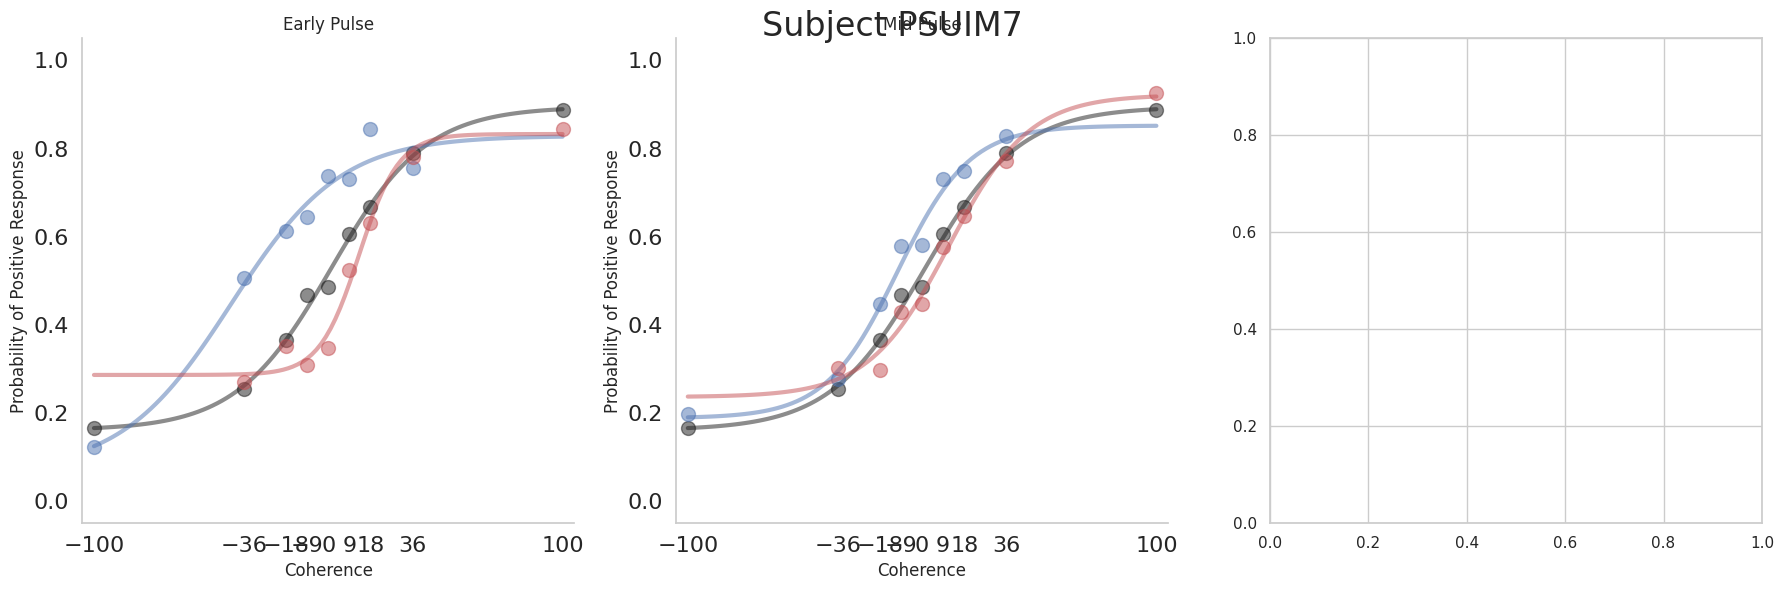

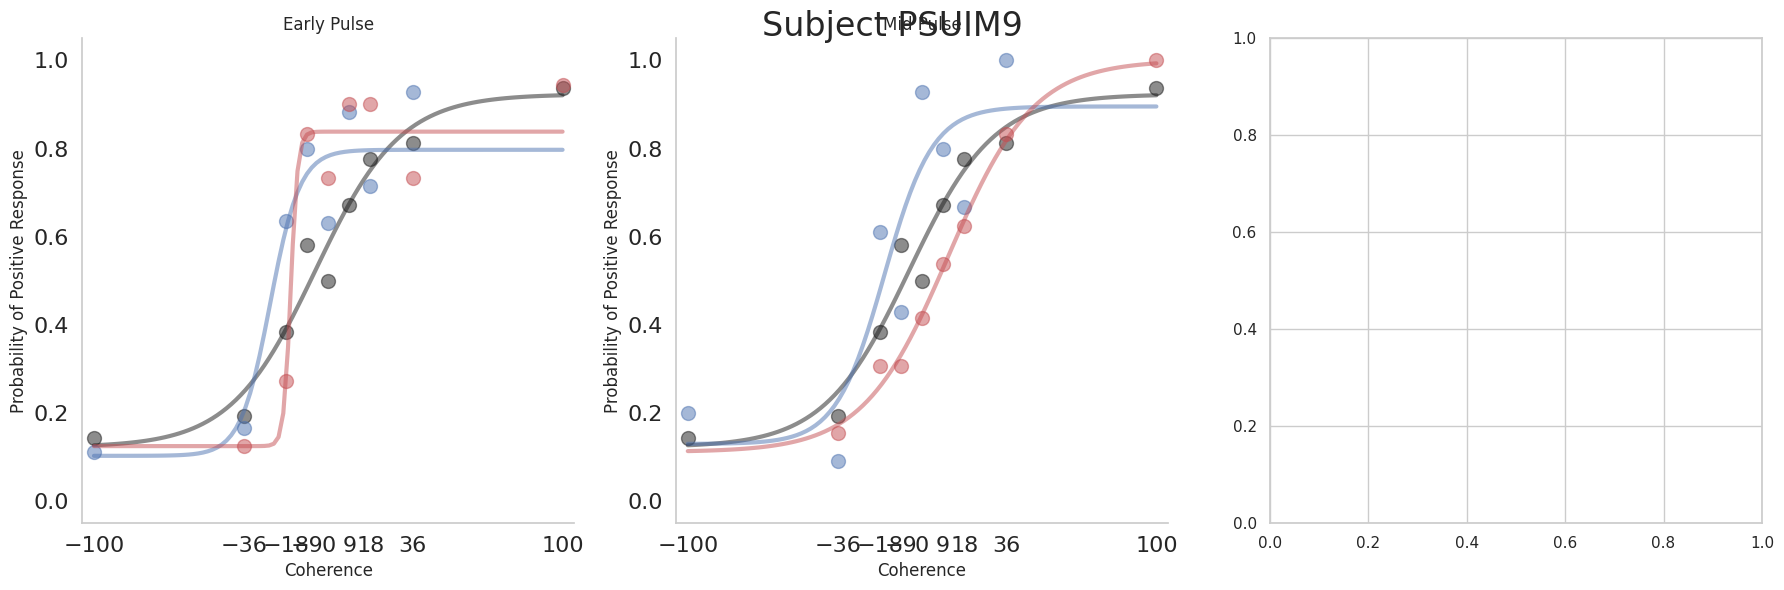

In [10]:
import numpy as np
from scipy import stats
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt

# fig, axs = plt.subplots(1, 3, figsize=(18, 6))

x_data, y_data = {}, {}

# 1️⃣ Plot each subject’s psychometric function (faint)
for subject_id in data.subject_id.unique():
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))
    plot_pulse_psych(pmf_data_by_subject[subject_id], legend=False, alpha=0.5, fig=fig, ax=axs)

    for pulse_type, vals in pmf_data_by_subject[subject_id].items():
        x_data.setdefault(pulse_type, []).append(vals["x"])
        y_data.setdefault(pulse_type, []).append(vals["y"])
    fig.suptitle(f"Subject {subject_id}", fontsize=24)
# 2️⃣ Determine a shared x grid for averaging
# all_x = np.concatenate([np.concatenate(v) for v in x_data.values()])
# x_common = np.linspace(np.nanmin(all_x), np.nanmax(all_x), 9)  # use 9 bins or your design’s coherence levels

# # 3️⃣ Build averaged psychometric curves with interpolation
# avg_psych_curves = {}

# for pulse_type in sorted(x_data.keys()):
#     y_interp_list = []

#     for x_subj, y_subj in zip(x_data[pulse_type], y_data[pulse_type]):
#         if len(x_subj) < 2:
#             continue  # skip incomplete data
#         f = interp1d(x_subj, y_subj, bounds_error=False, fill_value=np.nan)
#         y_interp_list.append(f(x_common))

#     y_interp_arr = np.vstack(y_interp_list)
#     y_mean = np.nanmean(y_interp_arr, axis=0)
#     y_sem = stats.sem(y_interp_arr, axis=0, nan_policy="omit")

#     # Fit psychometric model to mean data
#     model = pmf_utils.fit_psychometric_function(x_common, y_mean, trial_counts=None, model_type=main_config.acceptance_criteria.psych_model)
#     x_model_avg = np.linspace(-100, 100, 100)
#     y_model_avg = model.predict(x_model_avg)

#     avg_psych_curves[pulse_type] = {
#         "x": x_common,
#         "y": y_mean,
#         "y_err": y_sem,
#         "model": model,
#         "x_hat": x_model_avg,
#         "y_hat": y_model_avg,
#     }

# # 4️⃣ Overlay group-average psychometric functions (bold)
# plot_pulse_psych(avg_psych_curves, legend=False, alpha=1, fig=fig, ax=axs)

plt.show()


In [11]:
# fig, axs = plt.subplots(1, 3, figsize=(18, 6))

# x_data, y_data, x_hat, y_hat = {}, {}, {}, {}

# for subject_id in data.subject_id.unique():
#     plot_pulse_psych(pmf_data_by_subject[subject_id], legend=False, alpha=0.08, fig=fig, ax=axs)

#     for pulse_type in pmf_data_by_subject[subject_id]:
#         if pulse_type not in x_data:
#             x_data[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["x"]]
#             y_data[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["y"]]
#             x_hat[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["x_hat"]]
#             y_hat[pulse_type] = [pmf_data_by_subject[subject_id][pulse_type]["y_hat"]]
#         else:
#             y_data[pulse_type].append(pmf_data_by_subject[subject_id][pulse_type]["y"])
#             y_hat[pulse_type].append(pmf_data_by_subject[subject_id][pulse_type]["y_hat"])

# avg_psych_curves = {}
# for pulse_type in sorted(x_data.keys()):
#     x = np.nanmean(x_data[pulse_type], axis=0)
#     y = np.nanmean(y_data[pulse_type], axis=0)

#     model = pmf_utils.fit_psychometric_function(x, y, trial_counts=None, model_type="logit_3")
#     # Generate model predictions over a range of x values
#     x_model_avg = np.linspace(-100, 100, 100)
#     y_model_avg = model.predict(x_model_avg)

#     avg_psych_curves[pulse_type] = {
#         "x": x,
#         "y": y,
#         "y_err": stats.sem(y_data[pulse_type], axis=0, nan_policy="omit"),
#         "model": model,
#         "x_hat": x_model_avg,
#         "y_hat": y_model_avg,
#     }

# plot_pulse_psych(avg_psych_curves, legend=False, alpha=1, fig=fig, ax=axs)

# Calculating choice bias based on GLM including pulse information

Kiani et al 2008
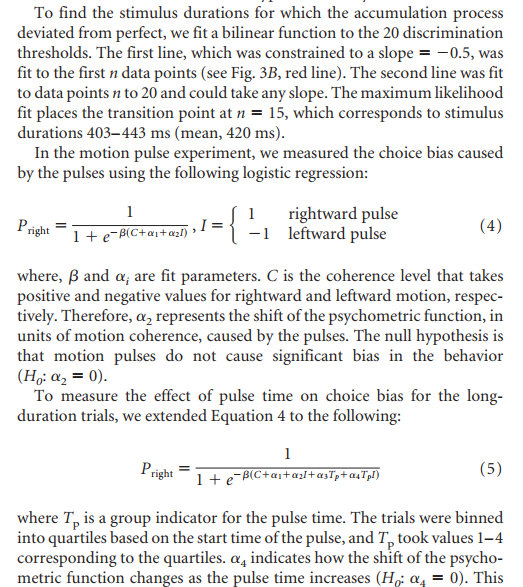

In [12]:
# def pulse_time_glm_fit(x,alpha_1,alpha_2,alpha_3,alpha_4,beta_1,beta_2,beta_3,beta_4,lapse,gamma):
#     coh, pulse_dir, pulse_time = x  # Unpack tuple input
#     beta = beta_1 + (beta_2 * pulse_time) + (beta_3 * (pulse_dir * pulse_time)) + (beta_4 * pulse_dir)
#     expon_eq = -beta * (coh + alpha_1 + (pulse_dir * alpha_2) + (alpha_3 * pulse_time) + (alpha_4 * (pulse_dir * pulse_time)))
#     return lapse + (1 - gamma - lapse) / (1 + np.exp(expon_eq))


# def fit(x, y):
#     # Parameter bounds
#     alpha_1 = (-1, 1)
#     alpha_2 = (-1, 1)
#     alpha_3 = (-1, 1)
#     alpha_4 = (-1, 1)
#     beta_1 = (1e-5, 30)
#     beta_2 = (-30, 30)
#     beta_3 = (-30, 30)
#     beta_4 = (-30, 30)
#     lapse = (0, 0.4)
#     gamma = (0, 0.4)

#     param_lims = [alpha_1, alpha_2, alpha_3, alpha_4, beta_1, beta_2, beta_3, beta_4, lapse, gamma]
#     _fit_func = pulse_time_glm_fit

#     # Prepare bounds and initial guess
#     bounds = list(zip(*param_lims))
#     initial_guess = [np.mean(b) for b in param_lims]  # Use the mean of bounds as initial guess

#     sigma = None

#     # Fit using curve_fit
#     popt, pcov = curve_fit(_fit_func, x, y, p0=initial_guess, bounds=bounds, sigma=sigma, absolute_sigma=False)

#     # Print results
#     print("Optimized Parameters:", popt)

#     return popt, pcov


In [64]:
def pulse_time_glm_fit(x, alpha_1, alpha_2, alpha_3, alpha_4, beta_1, beta_2, beta_3, beta_4, lapse_1, lapse_2, lapse_3, lapse_4, gamma_1, gamma_2, gamma_3, gamma_4):
    """Full GLM psychometric function with independent lapse and gamma effects."""
    coh, pulse_dir, pulse_time = x  # Unpack tuple input

    # Logistic slope parameter
    alpha = alpha_1 + (alpha_2 * pulse_dir) + (alpha_3 * pulse_time) + (alpha_4 * (pulse_dir * pulse_time))
    beta = beta_1 + (beta_2 * pulse_dir) + (beta_3 * pulse_time) + (beta_4 * (pulse_dir * pulse_time))

    # Compute lapse and gamma for each condition
    lapse = lapse_1 + (lapse_2 * pulse_dir) + (lapse_3 * pulse_time) + (lapse_4 * pulse_dir * pulse_time)
    gamma = gamma_1 + (gamma_2 * pulse_dir) + (gamma_3 * pulse_time) + (gamma_4 * pulse_dir * pulse_time)

    # Exponent and logistic equation
    expon_eq = -beta * (coh + alpha)

    # Logistic with dynamic lapse/gamma
    return lapse + (1 - gamma - lapse) / (1 + np.exp(expon_eq))


def fit(x, y):
    # Parameter bounds
    alpha_bounds = [(-30, 30), (-30, 30), (-30, 30), (-30, 30)]
    beta_bounds = [(-30, 30), (-30, 30), (-30, 30), (-30, 30)]
    lapse_bounds = [(0, 0.4), (-0.4, 0.4), (-0.4, 0.4), (-0.4, 0.4)]
    gamma_bounds = [(0, 0.4), (-0.4, 0.4), (-0.4, 0.4), (-0.4, 0.4)]

    param_lims = alpha_bounds + beta_bounds + lapse_bounds + gamma_bounds
    bounds = list(zip(*param_lims))
    initial_guess = [np.mean(b) for b in param_lims]

    # Fit using curve_fit
    popt, pcov = curve_fit(pulse_time_glm_fit, x, y, p0=initial_guess, bounds=bounds, maxfev=20000)

    print("Optimized Parameters:", popt)
    return popt, pcov

param_names = [
    "alpha_1","alpha_2","alpha_3","alpha_4",
    "beta_1","beta_2","beta_3","beta_4",
    "lapse_1","lapse_2","lapse_3","lapse_4",
    "gamma_1","gamma_2","gamma_3","gamma_4"
]


In [65]:
# Preprocess DataFrame
pulse_dir = data.pulse_type.map({1: 1, 2: 1, 3: 1, 0: 0, -1: -1, -2: -1, -3: -1}).to_numpy()
pulse_time = np.abs(data.pulse_type.to_numpy())
coh = data.signed_coherence.to_numpy() / 100
y = data.choice.to_numpy().astype(float)  # Ensure `choice` is numerical
x = (coh, pulse_dir, pulse_time)


# Fit model
fit_params, fit_cov = fit(x, y)
y_fitted = pulse_time_glm_fit(x, *fit_params)
fitted_data = pd.DataFrame(np.array(x).T, columns=["coh", "pulse_dir", "pulse_time"])
fitted_data["y_fitted"] = y_fitted


Optimized Parameters: [-2.78772189e-02  9.26541166e-02  4.77461009e-02 -4.94577111e-03
  4.88526921e+00 -2.21254240e+00  2.61740638e-01  1.15804481e+00
  1.40915698e-01 -5.70403211e-02 -3.49224372e-03  3.07319236e-02
  1.14737190e-01 -9.42348507e-02  3.24382876e-02  6.34889389e-02]


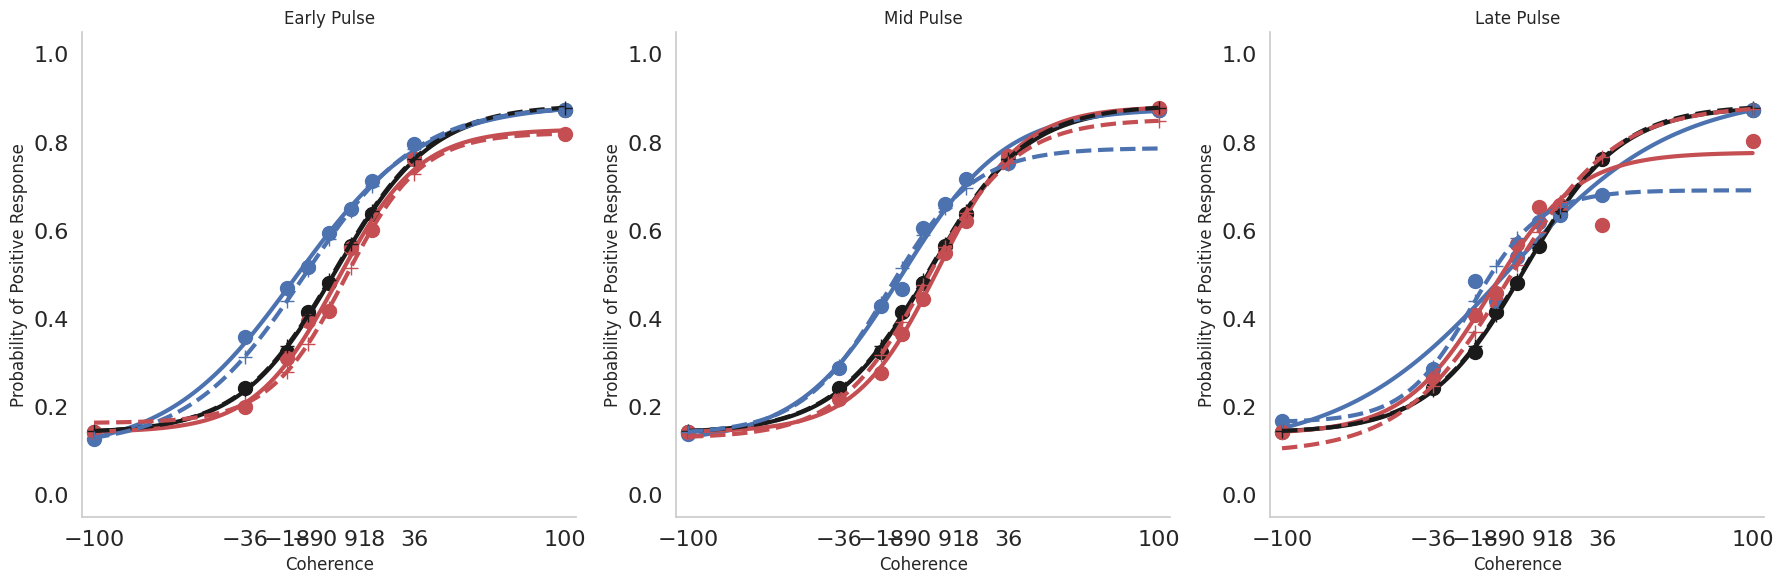

In [66]:
psych_curves = {}
psych_curves_glm = {}

for pulse_type in data.pulse_type.unique():
    x_data, y_data, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(data, pulse_type), model_type=main_config.psych_model, x_model_range=[-100, 100])

    psych_curves[pulse_type] = {
        "x": x_data,
        "y": y_data,
        "model": model,
        "x_hat": x_hat,
        "y_hat": y_hat,
    }


    pulse_dir = np.sign(pulse_type)
    pulse_time = np.abs(pulse_type)
    glm_data_subset = fitted_data[(fitted_data.pulse_dir == pulse_dir) & (fitted_data.pulse_time == pulse_time)]


    x_glm = np.sort(glm_data_subset.coh.unique())
    y_glm = []
    for coh in x_glm:
        coh_data = glm_data_subset[glm_data_subset.coh == coh]
        y_glm.append(coh_data.y_fitted.unique()[0])
    y_glm = np.array(y_glm)
    x_glm = x_glm * 100  # scale back to original coherence range

    model_glm = pmf_utils.fit_psychometric_function(x_glm, y_glm, trial_counts=None, model_type=main_config.psych_model)
    x_glm_hat = np.linspace(-100, 100, 100)
    # y_glm_hat = model.predict(x_glm_hat)
    y_glm_hat = model_glm.predict(x_glm_hat)

    psych_curves_glm[pulse_type] = {
        "x": x_glm,
        "y": y_glm,
        "model": model_glm,
        "x_hat": x_glm_hat,
        "y_hat": y_glm_hat,
    }

    # print(f"\nPulse type {pulse_type} fitted.")
    # print(np.round(y_glm, 2), np.round(y, 2))

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
plot_pulse_psych(psych_curves, legend=False, fig=fig, ax=axs)
plot_pulse_psych(psych_curves_glm, legend=False, ls="--", marker="+", ms=10, fig=fig, ax=axs);


In [67]:
import numpy as np
import pandas as pd
from scipy import stats

# Compute standard errors
param_se = np.sqrt(np.diag(fit_cov))

# Compute z-scores and p-values
z_scores = fit_params / param_se
p_values = 2 * (1 - stats.norm.cdf(np.abs(z_scores)))


# Build results DataFrame
fit_summary = pd.DataFrame({"coef": fit_params, "std_err": param_se, "z": z_scores, "p_value": p_values}, index=param_names)

print("\n📊 Fit summary:\n", fit_summary)



📊 Fit summary:
              coef   std_err          z   p_value
alpha_1 -0.027877  0.008854  -3.148635  0.001640
alpha_2  0.092654  0.034920   2.653314  0.007971
alpha_3  0.047746  0.009806   4.869135  0.000001
alpha_4 -0.004946  0.020119  -0.245821  0.805821
beta_1   4.885269  0.202252  24.154327  0.000000
beta_2  -2.212542  0.763083  -2.899479  0.003738
beta_3   0.261741  0.234810   1.114689  0.264984
beta_4   1.158045  0.442150   2.619124  0.008816
lapse_1  0.140916  0.008389  16.797031  0.000000
lapse_2 -0.057040  0.040354  -1.413503  0.157508
lapse_3 -0.003492  0.013857  -0.252021  0.801025
lapse_4  0.030732  0.025937   1.184845  0.236079
gamma_1  0.114737  0.008636  13.286432  0.000000
gamma_2 -0.094235  0.033744  -2.792609  0.005228
gamma_3  0.032438  0.007480   4.336628  0.000014
gamma_4  0.063489  0.016529   3.841126  0.000122


In [68]:
fit_summary

,coef,std_err,z,p_value
alpha_1,-0.027877,0.008854,-3.148635,0.001640
alpha_2,0.092654,0.034920,2.653314,0.007971
alpha_3,0.047746,0.009806,4.869135,0.000001
alpha_4,-0.004946,0.020119,-0.245821,0.805821
beta_1,4.885269,0.202252,24.154327,0.000000
beta_2,-2.212542,0.763083,-2.899479,0.003738
beta_3,0.261741,0.234810,1.114689,0.264984
beta_4,1.158045,0.442150,2.619124,0.008816
lapse_1,0.140916,0.008389,16.797031,0.000000
lapse_2,-0.057040,0.040354,-1.413503,0.157508


In [69]:
def get_param_and_se(pulse_type, fit_params_summary,param):
    pulse_dir = np.sign(pulse_type)
    pulse_time = np.abs(pulse_type)
    coefs = (pulse_dir * fit_params_summary['coef'][f"{param}_2"]) + (fit_params['coef'].loc[f"{param}_3"] * pulse_time) + (fit_params['coef'][f"{param}_4"] * (pulse_dir * pulse_time))
    # se =
    return coefs


In [73]:
def get_param_and_se(pulse_type, fit_params_summary, param):
    """
    Compute the predicted coefficient value (and optionally SE) for a given pulse_type.
    Assumes fit_params_summary is a DataFrame indexed by parameter name, e.g.:
        index = ["alpha_1", "alpha_2", "alpha_3", "alpha_4", ...]
        columns = ["coef", "se"]
    """
    pulse_dir = np.sign(pulse_type)
    pulse_time = np.abs(pulse_type)

    # safely access by .loc (your original code mixed array and string indexing)
    coef_1 = fit_params_summary.loc[f"{param}_1", "coef"]
    coef_2 = fit_params_summary.loc[f"{param}_2", "coef"]
    coef_3 = fit_params_summary.loc[f"{param}_3", "coef"]
    coef_4 = fit_params_summary.loc[f"{param}_4", "coef"]

    coef = (coef_1 +
            (coef_2 * pulse_dir) +
            (coef_3 * pulse_time) +
            (coef_4 * pulse_dir * pulse_time))

    return coef


In [74]:
# Get predictions
y_pred = pulse_time_glm_fit(x, *fit_params)
y_pred = np.clip(y_pred, 1e-6, 1 - 1e-6)

# Compute log-likelihood
y = np.asarray(y)
loglik = np.sum(y * np.log(y_pred) + (1 - y) * np.log(1 - y_pred))
n_params = len(fit_params)
aic = 2 * n_params - 2 * loglik
bic = np.log(len(y)) * n_params - 2 * loglik

# McFadden’s pseudo R²
null_p = np.mean(y)
loglik_null = np.sum(y * np.log(null_p) + (1 - y) * np.log(1 - null_p))
pseudo_r2 = 1 - (loglik / loglik_null)

print(f"\nModel Fit Stats:\nLogLik = {loglik:.2f}, AIC = {aic:.2f}, BIC = {bic:.2f}, McFadden R² = {pseudo_r2:.4f}")



Model Fit Stats:
LogLik = -19869.70, AIC = 39771.39, BIC = 39906.40, McFadden R² = 0.1601


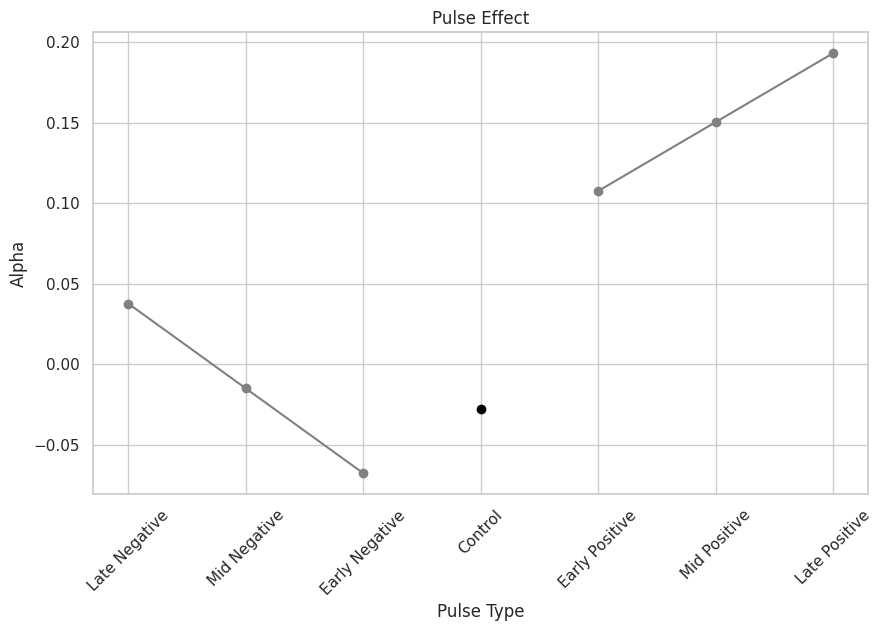

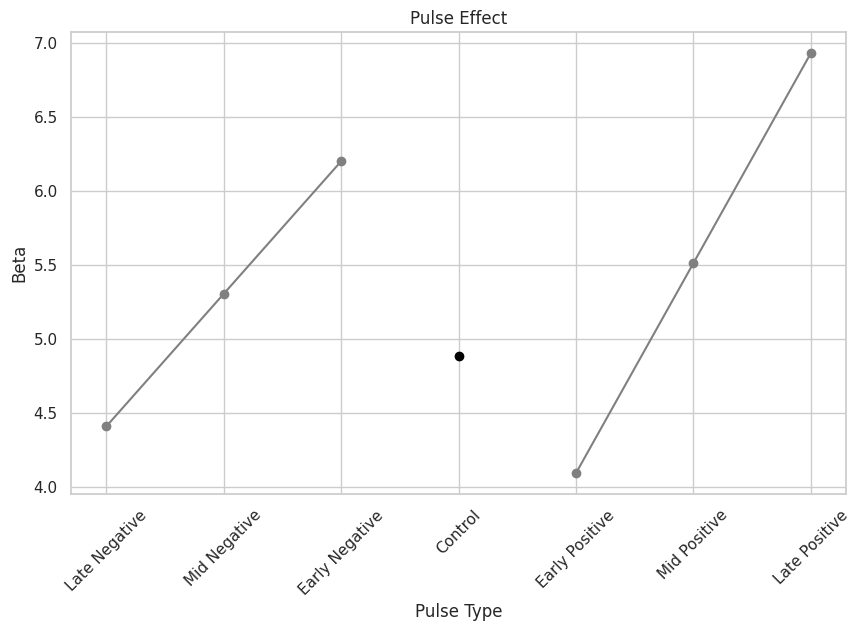

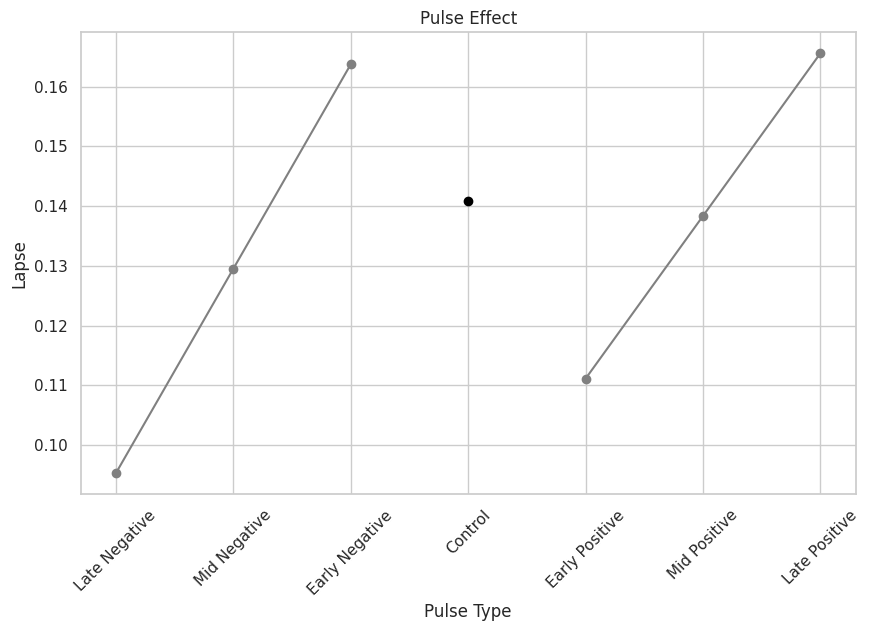

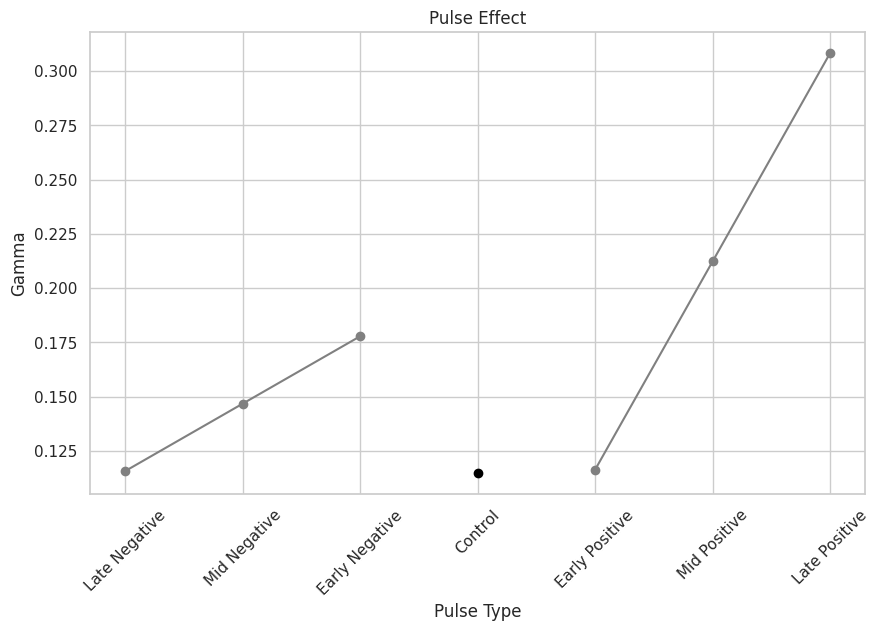

In [75]:
for param in ["alpha", "beta", "lapse", "gamma"]:

    plt.figure(figsize=(10, 6))
    pulses = [-3, -2, -1]
    plt.plot(pulses, [get_param_and_se(p, fit_summary, param) for p in pulses], "o-", color="gray")
    pulses = [1, 2, 3]
    plt.plot(pulses, [get_param_and_se(p, fit_summary, param) for p in pulses], "o-", color="gray")
    pulses = [0]
    plt.plot(pulses, [get_param_and_se(p, fit_summary, param) for p in pulses], "o-", color="black")

    plt.xticks([-3, -2, -1, 0, 1, 2, 3], ["Late Negative", "Mid Negative", "Early Negative", "Control", "Early Positive", "Mid Positive", "Late Positive"], rotation=45)
    plt.title("Pulse Effect")
    plt.xlabel("Pulse Type")
    plt.ylabel(param.capitalize());

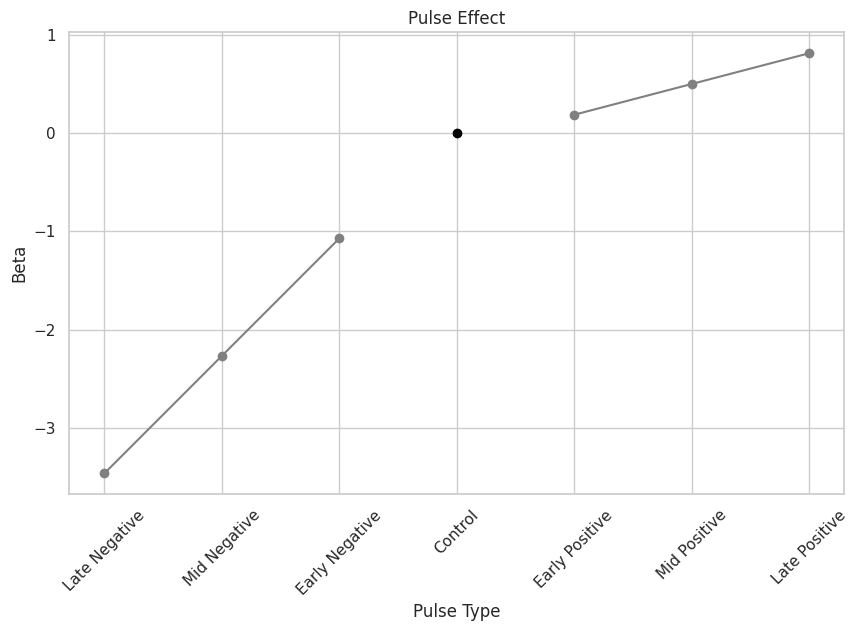

In [ ]:
def get_beta(pulse_type, model, fit_params):
    pulse_dir = np.sign(pulse_type)
    pulse_time = np.abs(pulse_type)
    if model == "pulse":
        beta = pulse_dir * fit_params[5]
    elif model == "pulse_time":
        beta = (pulse_dir * fit_params[5]) + (fit_params[6] * pulse_time) + (fit_params[7] * (pulse_dir * pulse_time))
    return beta

plt.figure(figsize=(10, 6))
pulses = [-3, -2, -1]
plt.plot(pulses, [get_beta(p, model, fit_params) for p in pulses], "o-", color="gray")
pulses = [1, 2, 3]
plt.plot(pulses, [get_beta(p, model, fit_params) for p in pulses], "o-", color="gray")
pulses = [0]
plt.plot(pulses, [get_beta(p, model, fit_params) for p in pulses], "o-", color="black")

plt.xticks([-3, -2, -1, 0, 1, 2, 3], ["Late Negative", "Mid Negative", "Early Negative", "Control", "Early Positive", "Mid Positive", "Late Positive"], rotation=45)
plt.title("Pulse Effect")
plt.xlabel("Pulse Type")
plt.ylabel("Beta");


## Statistics


📌 GLM Results for Pulse_Time Model:

                 Generalized Linear Model Regression Results                  
Dep. Variable:                 choice   No. Observations:                15698
Model:                            GLM   Df Residuals:                    15690
Model Family:                Binomial   Df Model:                            7
Link Function:                  logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -9476.5
Date:                Mon, 10 Nov 2025   Deviance:                       18953.
Time:                        02:05:36   Pearson chi2:                 1.59e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1608
Covariance Type:            nonrobust                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------

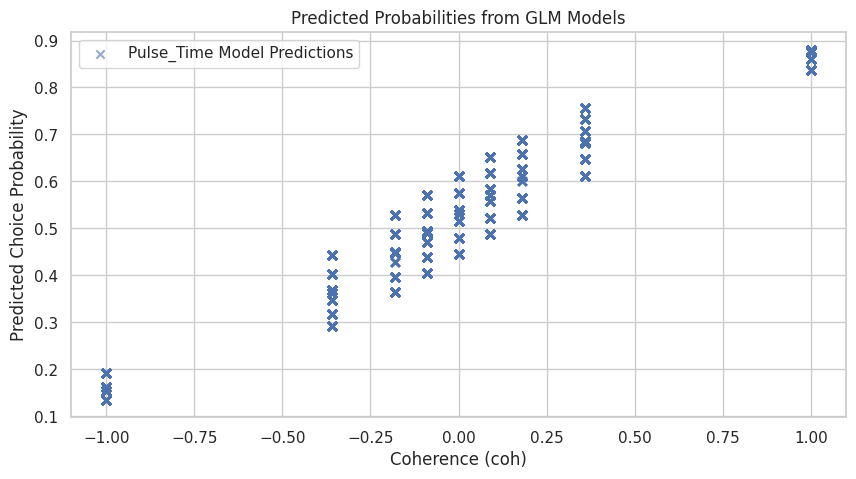

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Binomial
from statsmodels.genmod.families.links import logit
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

# Generate synthetic data similar to motion energy experiments
glm_data = pd.DataFrame(
    {
        "coh": data.signed_coherence / 100,  # Signed coherence (motion strength)
        "pulse_dir": data.pulse_type.map({1: 1, 2: 1, 3: 1, 0: 0, -1: -1, -2: -1, -3: -1}),  # Direction of the pulse
        "pulse_time": np.abs(data.pulse_type),  # Time of the pulse event
        "choice": data.choice.astype(float),  # Binary response (0 or 1)
    }
)

# ### **1️⃣ Fit GLM for Pulse Model (without pulse_time)**
# formula_pulse = "choice ~ coh + pulse_dir"
# glm_pulse = smf.glm(formula=formula_pulse, data=glm_data, family=Binomial(link=logit())).fit()

# print("\n📌 GLM Results for Pulse Model:\n")
# print(glm_pulse.summary())

### **2️⃣ Fit GLM for Pulse_Time Model (including pulse_time interaction)**
formula_pulse_time = "choice ~ coh + pulse_dir + pulse_time + pulse_dir:pulse_time + coh:pulse_time + coh:pulse_dir + coh:pulse_dir:pulse_time"
glm_pulse_time = smf.glm(formula=formula_pulse_time, data=glm_data, family=Binomial(link=logit())).fit()

print("\n📌 GLM Results for Pulse_Time Model:\n")
print(glm_pulse_time.summary())

### **3️⃣ Model Comparison using AIC (lower is better)**
print("\n✅ Model Comparison (Lower AIC is better):")
# print(f"AIC for Pulse Model: {glm_pulse.aic}")
print(f"AIC for Pulse_Time Model: {glm_pulse_time.aic}")

### **4️⃣ Predict probabilities using the fitted model**
# glm_data["predicted_choice_pulse"] = glm_pulse.predict(glm_data)
glm_data["predicted_choice_pulse_time"] = glm_pulse_time.predict(glm_data)


### **5️⃣ Plot Model Predictions**

plt.figure(figsize=(10, 5))
# plt.scatter(glm_data["coh"], glm_data["predicted_choice_pulse"], label="Pulse Model Predictions", alpha=0.6)
plt.scatter(glm_data["coh"], glm_data["predicted_choice_pulse_time"], label="Pulse_Time Model Predictions", alpha=0.6, marker="x")
plt.xlabel("Coherence (coh)")
plt.ylabel("Predicted Choice Probability")
plt.legend()
plt.title("Predicted Probabilities from GLM Models")
plt.show()

In [ ]:
glm_data.rename(columns={"choice": "data_choice"}, inplace=True)
glm_data["signed_coherence"] = glm_data["coh"] * 100
glm_data.rename(columns={"predicted_choice_pulse_time": "choice"}, inplace=True)


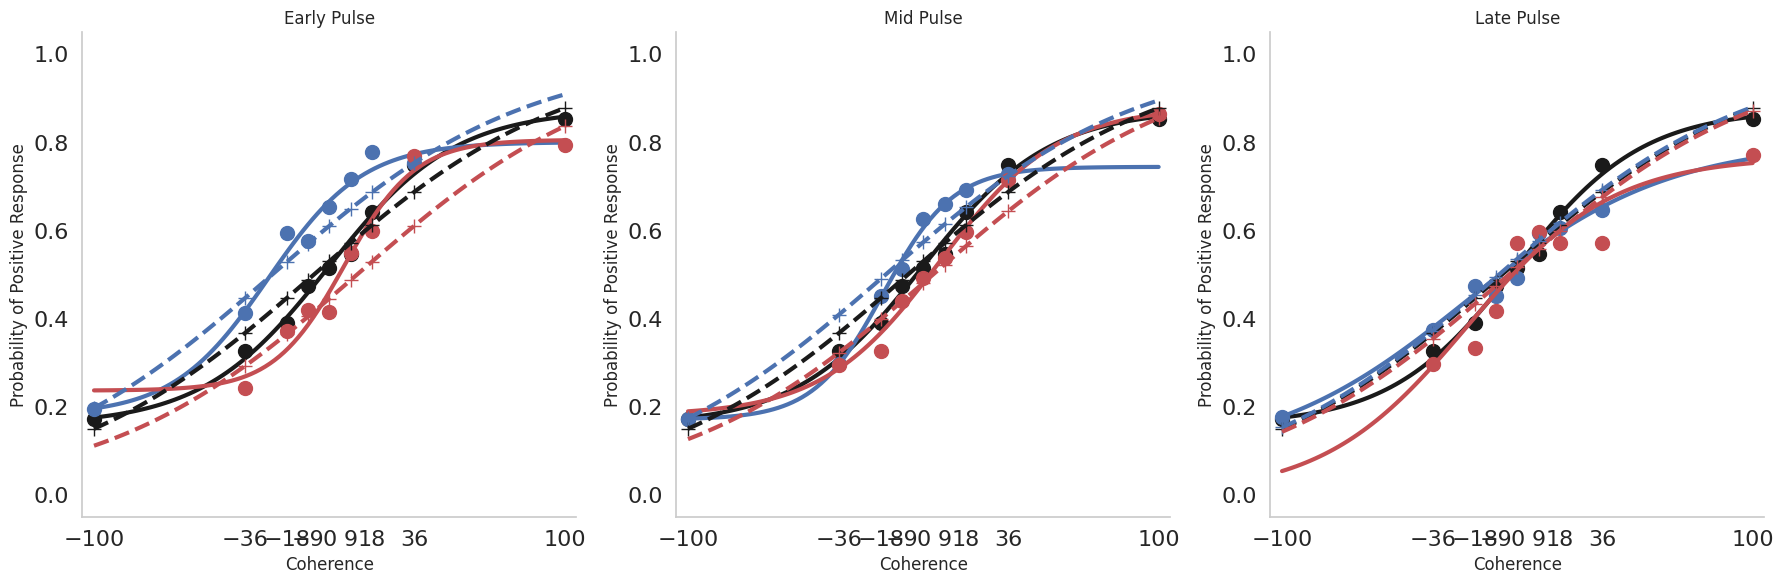

In [ ]:

psych_curves = {}
psych_curves_glm = {}

for pulse_type in data.pulse_type.unique():
    x, y, model, x_hat, y_hat = pmf_utils.get_psychometric_data(get_pulse_data(data, pulse_type), model_type=main_config.psych_model, x_model_range=[-100, 100])

    psych_curves[pulse_type] = {
        "x": x,
        "y": y,
        "model": model,
        "x_hat": x_hat,
        "y_hat": y_hat,
    }

    pulse_dir = np.sign(pulse_type)
    pulse_time = np.abs(pulse_type)
    glm_data_subset = glm_data[(glm_data.pulse_dir == pulse_dir) & (glm_data.pulse_time == pulse_time)]


    x_glm = np.sort(glm_data_subset.signed_coherence.unique())
    y_glm = []
    for coh in x_glm:
        coh_data = glm_data_subset[glm_data_subset.signed_coherence == coh]
        y_glm.append(coh_data.choice.unique()[0])
    y_glm = np.array(y_glm)

    model_glm = pmf_utils.fit_psychometric_function(x_glm, y_glm, trial_counts=None, model_type=main_config.psych_model)
    x_glm_hat = np.linspace(-100, 100, 100)
    # y_glm_hat = model.predict(x_glm_hat)
    y_glm_hat = model_glm.predict(x_glm_hat)

    psych_curves_glm[pulse_type] = {
        "x": x_glm,
        "y": y_glm,
        "model": model_glm,
        "x_hat": x_glm_hat,
        "y_hat": y_glm_hat,
    }


    # print(f"\nPulse type {pulse_type} fitted.")
    # print(np.round(y_glm, 2), np.round(y, 2))



fig, axs = plt.subplots(1, 3, figsize=(18, 6))
plot_pulse_psych(psych_curves, legend=False, fig=fig, ax=axs)
plot_pulse_psych(psych_curves_glm, legend=False, ls='--', marker='+', ms=10, fig=fig, ax=axs);
